# Serie III.4: precio, superficie y producción con rezagos

**La asociación más clara aparece en el agregado mundial a dos años; no se replica con suficiente utilidad en Guatemala. No se identifica causalidad ni un plazo agronómico demostrado.**

Este notebook responde exclusivamente al inciso 4 del PDF. [Respuestas centrales](../docs/respuestas-prueba.md) y [conclusiones completas](../docs/conclusiones-serie-III.md#4-respuesta-de-superficie-y-producción-al-precio) reúnen decisiones, magnitudes y límites. Requiere ejecutar el notebook 13 para obtener la vista auditada de FAOSTAT y disponer de `Sugar_data.csv`. Los análisis de los incisos 1–3 conservan sus resultados.

Guatemala es el caso de decisión local y `World` es el agregado publicado de contexto. No se suman como dos países ni se usan 112 países para multiplicar artificialmente las realizaciones del mismo precio mundial. Producción es caña en toneladas, no azúcar recuperada.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
RAIZ = Path.cwd() if (Path.cwd()/"scripts").exists() else Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0,str(RAIZ))
from scripts.analizar_oferta_serie3 import ejecutar
resumen = ejecutar(RAIZ)
OUT = RAIZ/"outputs/serie3_oferta"
panel = pd.read_csv(OUT/"panel_anual.csv")
corr = pd.read_csv(OUT/"correlaciones.csv")
ajustes = pd.read_csv(OUT/"ajustes.csv")
metricas = pd.read_csv(OUT/"metricas_temporales.csv")
omisiones = pd.read_csv(OUT/"omitir_un_ano.csv")
display(pd.Series(resumen,dtype=object).to_frame("Resultado"))

,Resultado
huellas,{'data\raw\serie3\Sugar_data.csv': '944471f40a...
filas_precio_crudo,6097
filas_precio_anual,5766
filas_precio_fuera,331
dias_marcados_sensibilidad,99
anos_precio_completo,23
celdas_faostat,27648
celdas_en_panel,138
celdas_fuera_panel,27510
filas_panel,46


## Datos, conservación y reloj del análisis

Se usan promedios de los cierres diarios nominales, centavos USD/libra, para **2001–2023**: 23 años completos, con presencia de los doce meses; no certifica que estén todas las sesiones esperadas. De 6,097 días se incluyen 5,766; los 331 de 2000 parcial y 2024 parcial/fuera del ámbito quedan en `precios_fuera_anual.csv`, con valores originales y motivos. No se eliminan picos por su magnitud.

Se seleccionan 138 celdas FAOSTAT (dos ámbitos × 23 años × tres indicadores). Las otras 27,510 de la vista de caña permanecen en `faostat_fuera_panel.csv`, con motivo geográfico/temporal; no son errores. Se conservan flags, unidad y fila de origen. Área en ha, producción en t y rendimiento en kg/ha: `producción ≈ área × rendimiento / 1,000`. No se tratan como tres causas independientes.

Los 46 años-ámbito pasan a **40 ecuaciones: 20 por ámbito, 2004–2023**, al exigir los mismos cambios y rezagos para todas las comparaciones. Los seis años iniciales se guardan aparte con motivo. No hay imputación. En Guatemala 14 de los 20 años tienen A en los tres indicadores; las otras combinaciones se muestran abajo. Un A de `World` no certifica que todos sus componentes sean mediciones oficiales independientes.

Año t es el año publicado de cosecha, no una fecha verificada de decisión o siembra. `precio t−1` es el promedio de todo el calendario anterior; `precio t−2`, el de dos años antes. No se conoce el calendario exacto de zafra ni la fecha de publicación/revisión de FAOSTAT. Es una alineación anual retrospectiva.

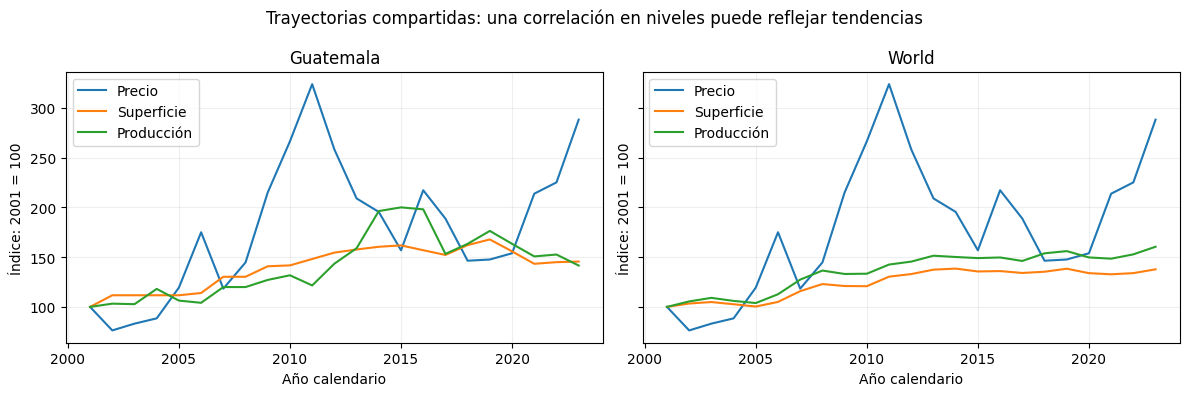

Años
area      flag_superficie flag_produccion flag_rendimiento      
Guatemala A               A               A                   14
                          E               E                    1
          E               A               E                    2
          I               A               E                    3
World     A               A               A                   20

In [2]:
fig, axes = plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,area in zip(axes,["Guatemala","World"]):
    g=panel[panel.area.eq(area)].set_index("ano")
    for col,etiqueta in [("precio","Precio"),("superficie","Superficie"),("produccion","Producción")]:
        ax.plot(g.index,100*g[col]/g[col].iloc[0],label=etiqueta)
    ax.set(title=area,xlabel="Año calendario",ylabel="Índice: 2001 = 100")
    ax.grid(alpha=.2);ax.legend()
fig.suptitle("Trayectorias compartidas: una correlación en niveles puede reflejar tendencias")
fig.tight_layout();fig.savefig(OUT/"trayectorias.png",dpi=150);plt.show()
display(panel[panel.en_muestra].groupby(["area","flag_superficie","flag_produccion","flag_rendimiento"]).size().rename("Años").to_frame())

## Niveles y cambios: misma muestra, tres rezagos predefinidos

Se comparan correlaciones de logaritmos de niveles y de cambios `gX_t = ln(X_t/X_{t−1})`, sin elegir solo la mayor. Los rezagos 0, 1 y 2 usan exactamente 2004–2023. El contemporáneo es descriptivo: parte del precio se observa después de decisiones agrícolas, por lo que no sirve como estímulo previo disponible.

A dos años, la correlación nivel precio/superficie es 0.845 en Guatemala; en cambios baja a **0.310**. Para producción cambia de 0.664 a **0.001**. No basta el nivel para defender respuesta local. En el mundo, la correlación de cambios a dos años sigue siendo **0.718 para superficie y 0.776 para producción**. Un año da solo 0.063 y 0.097. Dos años es el rezago con señal más clara entre los examinados; no se buscaron ventanas hasta conseguir ese resultado.

Diferenciar reduce el problema de tendencias compartidas, pero no demuestra estacionariedad ni descarta una relación de largo plazo. No se realiza cointegración ni inferencia de equilibrio con esta historia corta. [FPP3, capítulo 7](https://otexts.com/fpp3/regression.html), secciones 7.3, 7.4 y 7.8, fundamenta esas precauciones y la distinción entre asociación, predicción y causalidad.

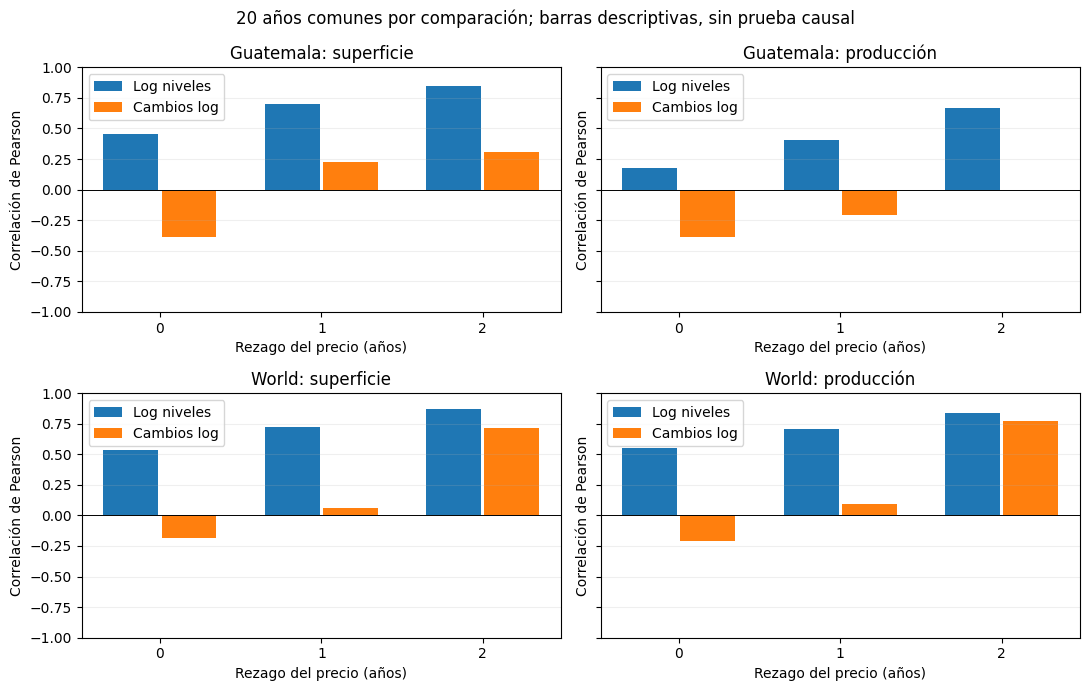

rezago                      0       1       2
area      objetivo                           
Guatemala produccion  -0.3910 -0.2113  0.0005
          rendimiento -0.2588 -0.3643 -0.1601
          superficie  -0.3907  0.2226  0.3105
World     produccion  -0.2074  0.0966  0.7755
          rendimiento -0.1660  0.1229  0.5313
          superficie  -0.1811  0.0634  0.7180

In [3]:
fig,axes=plt.subplots(2,2,figsize=(11,7),sharey=True)
for fila,area in enumerate(["Guatemala","World"]):
    for columna,obj in enumerate(["superficie","produccion"]):
        ax=axes[fila,columna]
        g=corr[corr.area.eq(area)&corr.objetivo.eq(obj)]
        for escala,desplazamiento,etiqueta in [("log",-.18,"Log niveles"),("g",.18,"Cambios log")]:
            valores=g[g.escala.eq(escala)].sort_values("rezago").r
            ax.bar(np.arange(3)+desplazamiento,valores,width=.34,label=etiqueta)
        ax.axhline(0,color="black",lw=.7);ax.set_ylim(-1,1)
        ax.set(title=f"{area}: {dict(superficie='superficie',produccion='producción')[obj]}",xlabel="Rezago del precio (años)",ylabel="Correlación de Pearson",xticks=[0,1,2])
        ax.legend();ax.grid(axis="y",alpha=.2)
fig.suptitle("20 años comunes por comparación; barras descriptivas, sin prueba causal")
fig.tight_layout();fig.savefig(OUT/"correlaciones.png",dpi=150);plt.show()
display(corr[corr.escala.eq("g")].pivot(index=["area","objetivo"],columns="rezago",values="r").round(4))

## Ecuaciones parsimoniosas y estabilidad

Se ajustan cuatro especificaciones fijas por mínimos cuadrados: media histórica del cambio; cambio propio anterior; dos cambios de precio anteriores; y ambos conjuntos. La ecuación controlada es:

`gX_t = α + φ·gX_{t−1} + β1·gP_{t−1} + β2·gP_{t−2} + error_t`.

Tiene cuatro parámetros para veinte observaciones; su R² describe ajuste interno, no acierto futuro. No se agregan controles que son componentes algebraicos de la respuesta. El rendimiento se usa para examinar la descomposición de producción, sin afirmar tres hallazgos independientes. No se calculan p-valores de réplicas independientes ni elasticidades causales.

En el mundo, β2 es **0.0986 en superficie y 0.1318 en producción** controlando el crecimiento previo. Omitir una ecuación anual a la vez mantiene sus rangos positivos: **0.0863–0.1061 y 0.1188–0.1387**. También sigue positivo en ambos bloques de diez años. En Guatemala, superficie tiene β1/β2 = 0.0609/0.0496 en el conjunto; β1 cambia de signo entre bloques. Producción da −0.1186/−0.0064; su β2 cambia de signo al omitir años. No hay respuesta local sólida de producción demostrada.

La omisión retira una ecuación; conserva ese año como antecedente de las demás. Sus rangos y los bloques son diagnósticos de sensibilidad, **no intervalos de confianza**. Las medias de meses equiponderados y la sensibilidad sin 99 días con OHLC inconsistente o volumen cero dan coeficientes próximos; esos días quedan con motivo en `dias_fuera_sensibilidad.csv`. Ninguna variante certifica el enlace de contratos ni elimina todos sus efectos.

In [4]:
principal=ajustes[ajustes.modelo.eq("propia_precio") & ajustes.variante.eq("precio")]
display(principal[["area","objetivo","bloque","n","intercepto","g_previa","p_1","p_2","r2"]].round(5))
display(omisiones.groupby(["area","objetivo"])[["p_1","p_2"]].agg(["min","max"]).round(5))
display(ajustes[ajustes.modelo.eq("propia_precio")&ajustes.bloque.eq("completo")][["area","objetivo","variante","p_1","p_2"]].round(5))

,area,objetivo,bloque,n,intercepto,g_previa,p_1,p_2,r2
3,Guatemala,superficie,completo,20,0.00533,0.20999,0.06089,0.04962,0.17693
4,Guatemala,superficie,2004_2013,10,0.02813,-0.16695,0.06897,0.02885,0.24614
5,Guatemala,superficie,2014_2023,10,-0.00264,0.24756,-0.03368,0.10229,0.27914
11,Guatemala,produccion,completo,20,0.02500,-0.11930,-0.11856,-0.00644,0.05608
12,Guatemala,produccion,2004_2013,10,0.08032,-0.53095,-0.11281,-0.04701,0.18470
13,Guatemala,produccion,2014_2023,10,-0.01594,-0.00010,-0.40552,0.02886,0.47571
19,Guatemala,rendimiento,completo,20,0.01623,-0.22658,-0.16180,-0.08529,0.19597
20,Guatemala,rendimiento,2004_2013,10,0.04088,-0.55943,-0.15816,-0.10462,0.30706
21,Guatemala,rendimiento,2014_2023,10,-0.01036,0.17580,-0.34213,0.00252,0.49841
27,World,superficie,completo,20,0.00557,0.27352,0.01448,0.09857,0.58802


p_1               p_2         
                           min      max      min      max
area      objetivo                                       
Guatemala produccion  -0.18599 -0.04218 -0.07476  0.03746
          rendimiento -0.20142 -0.09677 -0.14036 -0.04447
          superficie   0.02268  0.10168  0.02111  0.09117
World     produccion  -0.00305  0.03730  0.11878  0.13865
          rendimiento -0.00125  0.01471  0.02530  0.04518
          superficie  -0.00740  0.02573  0.08629  0.10615

,area,objetivo,variante,p_1,p_2
3,Guatemala,superficie,precio,0.06089,0.04962
6,Guatemala,superficie,precio_meses,0.06145,0.04982
7,Guatemala,superficie,precio_sin_marcas,0.06106,0.04961
11,Guatemala,produccion,precio,-0.11856,-0.00644
14,Guatemala,produccion,precio_meses,-0.11892,-0.00438
15,Guatemala,produccion,precio_sin_marcas,-0.12030,-0.00485
19,Guatemala,rendimiento,precio,-0.16180,-0.08529
22,Guatemala,rendimiento,precio_meses,-0.16254,-0.08392
23,Guatemala,rendimiento,precio_sin_marcas,-0.16324,-0.08394
27,World,superficie,precio,0.01448,0.09857


## Utilidad para años posteriores: diagnóstico retrospectivo

Se entrena primero en 2004–2013 y se estima 2014; después se añade únicamente cada año anterior y se repite hasta 2023. Son **diez evaluaciones por ámbito, variable y método**, sin selección posterior para publicar solo al ganador. Los precios explicativos terminan en t−1 y las etiquetas de ajuste también. No entra el precio contemporáneo o futuro.

Se utilizan las versiones finales de FAOSTAT, no las conocidas en cada fecha: la disponibilidad real de t−1 al inicio de t no está comprobada. La serie ya fue inspeccionada antes. Es una comprobación temporal condicional; no un backtest operativo con publicaciones históricas ni un periodo nuevo ciego.

El error es `100 × media(|gX observado − gX estimado|)`, **puntos logarítmicos**; no WAPE ni un porcentaje del volumen en toneladas. Un cambio log de 0.01 equivale aproximadamente a 1 % de crecimiento, pero la equivalencia no es exacta para cambios grandes.

En el mundo, precio solo reduce el MAE de producción de **3.201 a 1.425** puntos log (55.46 %) frente a media; para superficie de **2.241 a 1.874** (16.36 %). Al controlar crecimiento previo, añadir precio reduce de 3.035 a 1.685 en producción y de 1.882 a 1.767 en superficie. No se cuantifica rentabilidad.

En Guatemala, precio solo empeora la referencia media: superficie 4.249 → 4.540 y producción 9.838 → 10.339. Añadir precio al crecimiento propio mejora apenas 2.21 % superficie, pero continúa peor que la media; empeora producción 12.94 %. La señal mundial no autoriza trasladar la relación a las decisiones locales.

modelo                 media  propia   precio  propia_precio
area      objetivo                                          
Guatemala produccion  9.8379  9.9386  10.3394        11.2247
          superficie  4.2488  4.7596   4.5401         4.6542
World     produccion  3.2008  3.0353   1.4255         1.6847
          superficie  2.2411  1.8821   1.8744         1.7673

Guatemala, superficie: mejora precio/media = -6.86 %; añadir precio a propia = 2.21 %
Guatemala, produccion: mejora precio/media = -5.10 %; añadir precio a propia = -12.94 %
World, superficie: mejora precio/media = 16.36 %; añadir precio a propia = 6.10 %
World, produccion: mejora precio/media = 55.46 %; añadir precio a propia = 44.50 %


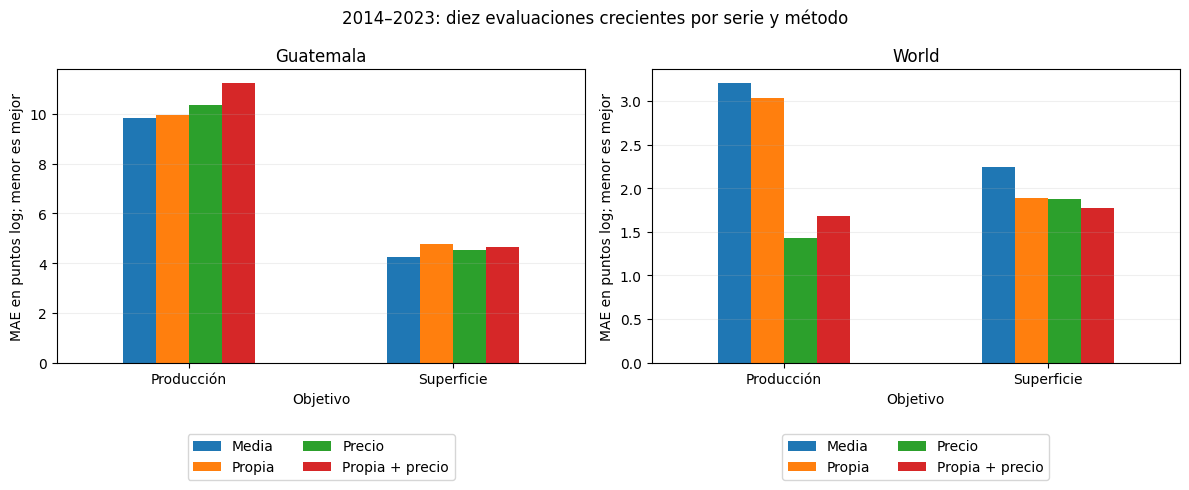

In [5]:
tabla=metricas[metricas.objetivo.isin(["superficie","produccion"])].pivot(index=["area","objetivo"],columns="modelo",values="MAE_puntos_log")
tabla=tabla[["media","propia","precio","propia_precio"]]
display(tabla.round(4))
for area in ["Guatemala","World"]:
    for objetivo in ["superficie","produccion"]:
        r=tabla.loc[(area,objetivo)]
        print(f"{area}, {objetivo}: mejora precio/media = {100*(1-r.precio/r.media):.2f} %; añadir precio a propia = {100*(1-r.propia_precio/r.propia):.2f} %")
fig,axes=plt.subplots(1,2,figsize=(12,5.2))
for ax,area in zip(axes,["Guatemala","World"]):
    tabla.loc[area].rename(index={"produccion":"Producción","superficie":"Superficie"},columns={"media":"Media","propia":"Propia","precio":"Precio","propia_precio":"Propia + precio"}).plot.bar(ax=ax,rot=0)
    ax.set(title=area,xlabel="Objetivo",ylabel="MAE en puntos log; menor es mejor")
    ax.grid(axis="y",alpha=.2)
    ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),ncol=2,title=None)
fig.suptitle("2014–2023: diez evaluaciones crecientes por serie y método")
fig.tight_layout();fig.savefig(OUT/"errores_temporales.png",dpi=150);plt.show()

## Interpretación gerencial, causalidad y certeza

**Decisión:** mantener la relación mundial a dos años como contexto de escenarios de oferta; no usarla para ordenar expansión de superficie en Guatemala ni atribuir a una subida del futuro un aumento determinado de caña. La utilidad cuantificada es la reducción de error retrospectivo del agregado, no ahorro, ingreso o beneficio causal de Santa Ana.

Un incentivo de precio puede relacionarse con nuevas siembras, renovación, insumos o capacidad, y su cosecha aparecer después. El [caso histórico de Tailandia documentado por FAO](https://www.fao.org/4/x0513e/x0513e24.htm) muestra que calendario, socas, políticas, capacidad y clima acompañan esos procesos. Motiva considerar rezagos; no fija el plazo de Guatemala.

La precedencia temporal no identifica causalidad: los futuros pueden anticipar escasez/cosechas, la oferta puede afectar precios y un clima persistente puede afectar ambos con retraso. Faltan expectativas y shocks exógenos identificados; no se estima un experimento ni un efecto Granger como prueba causal. La muestra de veinte años es pequeña, los cambios pueden seguir dependiendo entre sí y las agregaciones pueden ocultar respuestas nacionales distintas.

El área FAOSTAT es **cosechada**, no nueva siembra o decisión de expansión. El objetivo es caña, no azúcar comercial; faltan recuperación industrial y desvíos de uso. El futuro es nominal en USD y de continuidad parcialmente verificada, sin precio físico recibido, tipo de cambio, inflación, costos o retornos de cultivos alternativos. Agregar anualmente suaviza días, sin resolver esos problemas. No se fija un rezago óptimo físico ni una elasticidad de largo plazo.

Para una decisión propia hacen falta fechas de siembra/renovación/cosecha por parcela, precio esperado al decidir y precio neto recibido, costos/márgenes alternativos, clima/agua y capacidad. Su captura permitiría contrastar un mecanismo concreto y buscar variación de precio exógena; no se afirma identificación solo por añadir controles.

**Certeza:** reproducción aritmética y orientación temporal comprobables; evidencia asociativa mundial moderada y condicionada; insuficiente para una regla local o efecto causal. Los cuatro incisos de Serie III tienen respuesta analítica con estas reservas. Series IV y V permanecen pendientes.

[Pruebas unitarias](../tests/unitarias/test_oferta_serie3.py) y [contrastes independientes](../tests/integracion/test_oferta_serie3_resultados.py) revisan datos, unidades, flags, conservación, rezagos, coeficientes, perturbación futura y todas las predicciones/errores. Los resultados se conservan en `outputs/serie3_oferta/`, fuera de Git. Reproducción desde la raíz:

```powershell
python -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=600 notebooks/17_oferta_precio_serie3.ipynb
python -m pytest tests/unitarias/test_oferta_serie3.py tests/integracion/test_oferta_serie3_resultados.py -q
```